## Step 1 – Load the 4 hospitals

In [1]:
import pandas as pd
import numpy as np

cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

hospitals = {
    "Cleveland":   "processed.cleveland.data",
    "Hungary":     "processed.hungarian.data",
    "Switzerland": "processed.switzerland.data",
    "VA":          "processed.va.data",
}

frames = []
for name, file in hospitals.items():
    d = pd.read_csv(f"../data/UCI/{file}", header=None, names=cols, na_values="?")
    d["hospital"] = name
    frames.append(d)

df = pd.concat(frames, ignore_index=True)

# Target: 0 = no disease, 1-4 = disease  ->  convert to 0/1
df["target"] = (df["num"] > 0).astype(int)

print(df.shape)
df.groupby("hospital")["target"].agg(["count", "mean"]).round(2)

(920, 16)


,count,mean
hospital,,
Cleveland,303,0.46
Hungary,294,0.36
Switzerland,123,0.93
VA,200,0.74


## Step 2 – Clean

In [2]:
# 1. Drop columns that are mostly empty at 3 of the 4 hospitals
df = df.drop(columns=["num", "slope", "ca", "thal"])

# 2. Cholesterol or blood pressure of 0 is impossible -> mark as missing
df.loc[df["chol"] == 0, "chol"] = np.nan
df.loc[df["trestbps"] == 0, "trestbps"] = np.nan

print(df.shape)

# 3. Missing values per hospital
df.drop(columns=["target"]).isna().groupby(df["hospital"]).sum()

(920, 12)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,hospital
hospital,,,,,,,,,,,
Cleveland,0,0,0,0,0,0,0,0,0,0,0
Hungary,0,0,0,1,23,8,1,1,1,0,0
Switzerland,0,0,0,2,123,75,1,1,1,6,0
VA,0,0,0,57,56,7,0,53,53,56,0


## Step 3 – Prepare data per hospital

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Chest pain type is a category (1-4), not a number -> one column per type
df = pd.get_dummies(df, columns=["cp"], prefix="cp", dtype=int)
features = [c for c in df.columns if c not in ("hospital", "target")]

# Each hospital keeps its own 70% train / 30% test split
data = {}
for h, g in df.groupby("hospital", sort=False):
    X_tr, X_te, y_tr, y_te = train_test_split(
        g[features], g["target"], test_size=0.3, stratify=g["target"], random_state=42)
    data[h] = (X_tr, X_te, y_tr, y_te)
    print(f"{h:12s} train={len(X_tr):3d}  test={len(X_te):3d}  "
          f"(test: {y_te.sum()} sick, {(y_te==0).sum()} healthy)")

# Shared preprocessing: only summary numbers (medians, means) are shared, never patient rows
X_train_all = pd.concat([d[0] for d in data.values()])
imputer = SimpleImputer(strategy="median").fit(X_train_all)
scaler = StandardScaler().fit(imputer.transform(X_train_all))
prep = lambda X: scaler.transform(imputer.transform(X))

Cleveland    train=212  test= 91  (test: 42 sick, 49 healthy)
Hungary      train=205  test= 89  (test: 32 sick, 57 healthy)
Switzerland  train= 86  test= 37  (test: 35 sick, 2 healthy)
VA           train=140  test= 60  (test: 45 sick, 15 healthy)


## Step 4 – Local only vs Centralised

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Centralised: one model trained on ALL hospitals' training data pooled
y_train_all = pd.concat([d[2] for d in data.values()])
central = LogisticRegression(max_iter=2000).fit(prep(X_train_all), y_train_all)

rows = []
for h, (X_tr, X_te, y_tr, y_te) in data.items():
    local = LogisticRegression(max_iter=2000).fit(prep(X_tr), y_tr)   # this hospital only
    rows.append({
        "hospital": h,
        "local_only_AUC":  roc_auc_score(y_te, local.predict_proba(prep(X_te))[:, 1]),
        "centralised_AUC": roc_auc_score(y_te, central.predict_proba(prep(X_te))[:, 1]),
    })

results = pd.DataFrame(rows).round(3)
results

,hospital,local_only_AUC,centralised_AUC
0,Cleveland,0.892,0.896
1,Hungary,0.912,0.890
2,Switzerland,0.457,0.371
3,VA,0.723,0.785


## Step 5 – Federated Averaging (FedAvg)

In [5]:
from sklearn.metrics import log_loss

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# --- What each HOSPITAL does: train locally, starting from the global model ---
def local_train(w, b, X, y, epochs=5, lr=0.1, l2=0.01):
    for _ in range(epochs):
        p = sigmoid(X @ w + b)                 # current predictions
        error = p - y
        w = w - lr * (X.T @ error / len(y) + l2 * w)   # adjust weights
        b = b - lr * error.mean()
    return w, b

# Each hospital's private training data (stays "inside" the hospital)
clients = {h: (prep(d[0]), d[2].values) for h, d in data.items()}
n_total = sum(len(y) for _, y in clients.values())

# Combined test set (only used by us to measure progress)
X_test_all = np.vstack([prep(d[1]) for d in data.values()])
y_test_all = np.concatenate([d[3].values for d in data.values()])

# --- What the SERVER does ---
w_global = np.zeros(len(features))
b_global = 0.0
history = []

for rnd in range(1, 51):                                  # 50 rounds
    updates = []
    for h, (X, y) in clients.items():
        w_local, b_local = local_train(w_global.copy(), b_global, X, y)
        updates.append((w_local, b_local, len(y)))        # only weights are sent back

    # Weighted average: bigger hospitals count more
    w_global = sum(n * w for w, b, n in updates) / n_total
    b_global = sum(n * b for w, b, n in updates) / n_total

    p = sigmoid(X_test_all @ w_global + b_global)
    history.append({"round": rnd, "AUC": roc_auc_score(y_test_all, p), "loss": log_loss(y_test_all, p)})

history = pd.DataFrame(history)
history.iloc[[0, 4, 9, 19, 49]].round(3)

,round,AUC,loss
0,1,0.882,0.585
4,5,0.882,0.461
9,10,0.882,0.435
19,20,0.882,0.428
49,50,0.881,0.429


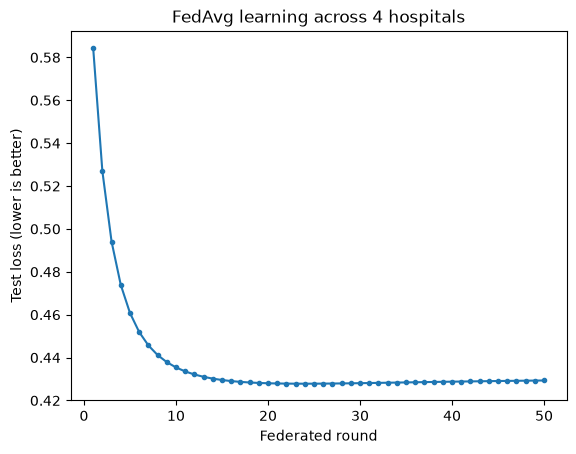

In [6]:
import matplotlib.pyplot as plt

plt.plot(history["round"], history["loss"], "o-", markersize=3)
plt.xlabel("Federated round"); plt.ylabel("Test loss (lower is better)")
plt.title("FedAvg learning across 4 hospitals")
plt.savefig("../outputs/fedavg_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
results["federated_AUC"] = [
    roc_auc_score(d[3], sigmoid(prep(d[1]) @ w_global + b_global)) for d in data.values()
]

overall = pd.DataFrame([{
    "hospital": "ALL (combined test)",
    "local_only_AUC": np.nan,
    "centralised_AUC": roc_auc_score(y_test_all, central.predict_proba(X_test_all)[:, 1]),
    "federated_AUC":  roc_auc_score(y_test_all, sigmoid(X_test_all @ w_global + b_global)),
}])

pd.concat([results, overall], ignore_index=True).round(3)

,hospital,local_only_AUC,centralised_AUC,federated_AUC
0,Cleveland,0.892,0.896,0.897
1,Hungary,0.912,0.890,0.890
2,Switzerland,0.457,0.371,0.400
3,VA,0.723,0.785,0.785
4,ALL (combined test),NaN,0.880,0.881


## Results summary – Federated learning (UCI, 4 hospitals)

| Hospital | Local only | Centralised | Federated |
|---|---|---|---|
| Cleveland | 0.892 | 0.896 | 0.897 |
| Hungary | 0.912 | 0.890 | 0.890 |
| VA | 0.723 | 0.785 | 0.785 |
| **All (combined test)** | – | **0.880** | **0.881** |

- FedAvg matched centralised performance without sharing patient records
- VA (smallest, most missing data) gained most from federation (0.72 → 0.79)
- Switzerland excluded from interpretation: test set has only 2 healthy patients
- Model: logistic regression, 50 rounds, 5 local epochs, weighted averaging by hospital size